In [15]:
%pip uninstall -y keras-nlp
%pip install -q "keras==3.15.1" "keras-hub==0.33.0" "datasets" "rouge-score"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

import tensorflow as tf
import keras
import keras_hub

from datasets import load_dataset
from rouge_score import rouge_scorer

os.environ["KERAS_BACKEND"] = "tensorflow"

In [17]:
MODEL_PRESET = "t5_small_multi"

MAX_ENCODER_LENGTH = 384
MAX_DECODER_LENGTH = 80

BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 3e-5
RANDOM_SEED = 42

keras.utils.set_random_seed(RANDOM_SEED)

AUTOTUNE = tf.data.AUTOTUNE

In [18]:
dataset = load_dataset("knkarthick/samsum")

In [19]:
train_data = dataset["train"]
val_data = dataset["validation"]
test_data = dataset["test"]

In [20]:
print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Test examples:", len(test_data))

Training examples: 14731
Validation examples: 818
Test examples: 819


In [21]:
print("\nExample dialogue:")
print(train_data[0]["dialogue"])

print("\nReference summary:")
print(train_data[0]["summary"])


Example dialogue:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

Reference summary:
Amanda baked cookies and will bring Jerry some tomorrow.


In [22]:
def make_dataset(split, training=False):
    dialogues = ["summarize: " + text for text in list(split["dialogue"])]
    summaries = list(split["summary"])
    data = {
        "encoder_text": dialogues,
        "decoder_text": summaries
    }

    ds = tf.data.Dataset.from_tensor_slices(data)

    if training:
        ds = ds.shuffle(
            buffer_size=len(split),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

In [23]:
train_ds = make_dataset(train_data, training=True)
val_ds = make_dataset(val_data)
test_ds = make_dataset(test_data)

In [24]:
print("One training batch:")
for batch in train_ds.take(1):
    print("Input keys:", batch.keys())
    print("Number of dialogues:", len(batch["encoder_text"]))
    print("First dialogue:", batch["encoder_text"][0].numpy().decode("utf-8")[:250])
    print("First summary:", batch["decoder_text"][0].numpy().decode("utf-8"))

One training batch:
Input keys: dict_keys(['encoder_text', 'decoder_text'])
Number of dialogues: 16
First dialogue: summarize: Alexis: i want to congratulate you
Alexis: i read your essay on how poverty is protrayed in oliver twist
Alexis: it was materful!
Trevor: i can't believe i'm hearing that!!!
Trevor: those words coming from you mean the world to me :-D
Trev
First summary: Trevor's essay on "Oliver Twist" was outstanding.


In [25]:
preprocessor = keras_hub.models.T5Seq2SeqLMPreprocessor.from_preset(
    MODEL_PRESET,
    encoder_sequence_length=MAX_ENCODER_LENGTH,
    decoder_sequence_length=MAX_DECODER_LENGTH
)

model = keras_hub.models.T5Seq2SeqLM.from_preset(
    MODEL_PRESET,
    preprocessor=preprocessor
)

print("Model:", type(model).__name__)
print("Preprocessor:", type(model.preprocessor).__name__)
print("Parameters:", f"{model.count_params():,}")

Model: T5Seq2SeqLM
Preprocessor: T5Seq2SeqLMPreprocessor
Parameters: 60,506,624


In [26]:
optimizer = keras.optimizers.AdamW(
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    global_clipnorm=1.0
)

model.compile(
    optimizer=optimizer,
    loss="auto",
    weighted_metrics=["accuracy"],
    sampler="greedy"
)

print("Model compiled successfully.")

Model compiled successfully.


In [27]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.CSVLogger("t5_samsum_training_log.csv")
]

In [28]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 584s 536ms/step - accuracy: 0.5318 - loss: 0.7753 - val_accuracy: 0.5764 - val_loss: 0.6588
Epoch 2/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 426s 462ms/step - accuracy: 0.5578 - loss: 0.7176 - val_accuracy: 0.5860 - val_loss: 0.6386
Epoch 3/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 425s 461ms/step - accuracy: 0.5681 - loss: 0.6943 - val_accuracy: 0.5917 - val_loss: 0.6269
Epoch 4/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 425s 461ms/step - accuracy: 0.5754 - loss: 0.6778 - val_accuracy: 0.5988 - val_loss: 0.6190
Epoch 5/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 425s 461ms/step - accuracy: 0.5816 - loss: 0.6647 - val_accuracy: 0.6006 - val_loss: 0.6149
Epoch 6/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 424s 460ms/step - accuracy: 0.5871 - loss: 0.6544 - val_accuracy: 0.6030 - val_loss: 0.6113
Epoch 7/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 423s 459ms/step - accuracy: 0.5912 - loss: 0.6442 - val_accuracy: 0.6059 - val_loss: 0.6066
Epoch 8/30
921/921 ━━━━━━━━━━━━━━━━━━━━ 423s 459ms/step - accuracy: 0.5955 -

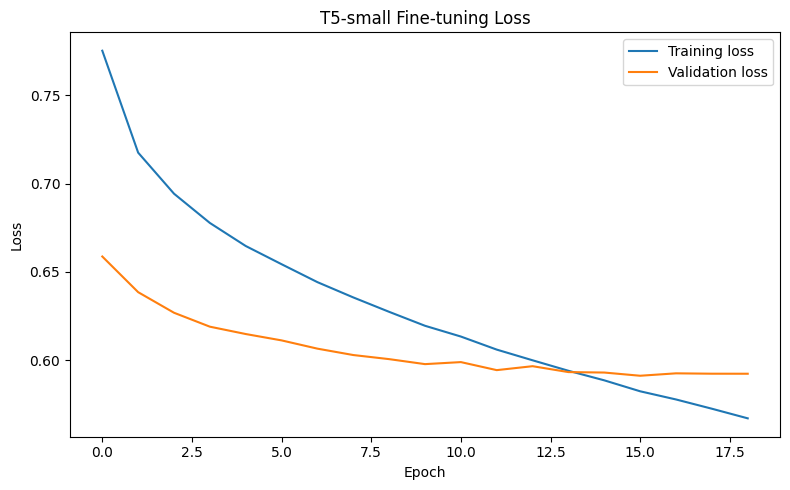

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("T5-small Fine-tuning Loss")
plt.legend()
plt.tight_layout()
plt.show()

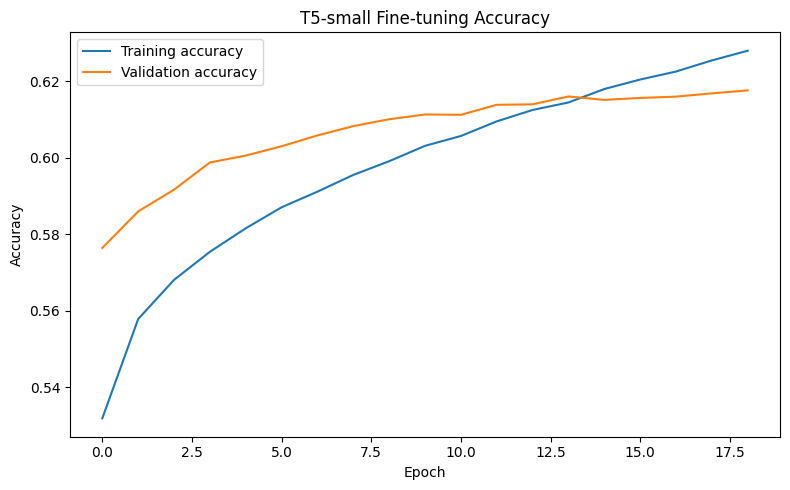

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("T5-small Fine-tuning Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
sample_indices = [0, 1, 2]

for index in sample_indices:
    dialogue = test_data[index]["dialogue"]
    reference = test_data[index]["summary"]
    prediction = model.generate("summarize: " + dialogue, max_length=MAX_DECODER_LENGTH)

    print("=" * 90)
    print("DIALOGUE:")
    print(dialogue)
    print("\nREFERENCE SUMMARY:")
    print(reference)
    print("\nGENERATED SUMMARY:")
    print(prediction)

DIALOGUE:
Hannah: Hey, do you have Betty's number?
Amanda: Lemme check
Hannah: <file_gif>
Amanda: Sorry, can't find it.
Amanda: Ask Larry
Amanda: He called her last time we were at the park together
Hannah: I don't know him well
Hannah: <file_gif>
Amanda: Don't be shy, he's very nice
Hannah: If you say so..
Hannah: I'd rather you texted him
Amanda: Just text him 🙂
Hannah: Urgh.. Alright
Hannah: Bye
Amanda: Bye bye

REFERENCE SUMMARY:
Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.

GENERATED SUMMARY:
Betty's number is Lemme. Amanda can't find it. Larry called Betty last time they were at the park together.
DIALOGUE:
Eric: MACHINE!
Rob: That's so gr8!
Eric: I know! And shows how Americans see Russian ;)
Rob: And it's really funny!
Eric: I know! I especially like the train part!
Rob: Hahaha! No one talks to the machine like that!
Eric: Is this his only stand-up?
Rob: Idk. I'll check.
Eric: Sure.
Rob: Turns out no! There are some of his stand-ups on you

In [32]:
test_dialogues = ["summarize: " + text for text in test_data["dialogue"]]
reference_summaries = list(test_data["summary"])
predictions = []

for start in range(0, len(test_dialogues), BATCH_SIZE):
    batch_dialogues = test_dialogues[start:start + BATCH_SIZE]

    batch_predictions = model.generate(
        batch_dialogues,
        max_length=MAX_DECODER_LENGTH
    )

    predictions.extend(list(batch_predictions))

    if (start // BATCH_SIZE + 1) % 20 == 0:
        print(f"Generated {len(predictions)} / {len(test_dialogues)} summaries")

print("Total predictions:", len(predictions))

Generated 320 / 819 summaries
Generated 640 / 819 summaries
Total predictions: 819


In [33]:
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

rouge_scores = {
    "rouge1": [],
    "rouge2": [],
    "rougeL": []
}

for reference, prediction in zip(reference_summaries, predictions):
    scores = scorer.score(reference, prediction)

    for metric in rouge_scores:
        rouge_scores[metric].append(scores[metric].fmeasure)

mean_rouge = {
    metric: float(np.mean(values))
    for metric, values in rouge_scores.items()
}

print("Test ROUGE scores:")
for metric, score in mean_rouge.items():
    print(f"{metric}: {score:.4f}")

Test ROUGE scores:
rouge1: 0.4660
rouge2: 0.2185
rougeL: 0.3837


In [34]:
results_df = pd.DataFrame({
    "dialogue": test_data["dialogue"],
    "reference_summary": reference_summaries,
    "generated_summary": predictions
})

display(results_df.head(10))

results_df.to_csv("t5_samsum_test_predictions.csv", index=False)
print("Saved predictions to t5_samsum_test_predictions.csv")

,dialogue,reference_summary,generated_summary
0,"Hannah: Hey, do you have Betty's number?\nAman...",Hannah needs Betty's number but Amanda doesn't...,Betty's number is Lemme. Amanda can't find it....
1,Eric: MACHINE!\nRob: That's so gr8!\nEric: I k...,Eric and Rob are going to watch a stand-up on ...,Eric likes the train part and shows how Americ...
2,"Lenny: Babe, can you help me with something?\n...",Lenny can't decide which trousers to buy. Bob ...,Bob will help Lenny with her outfit choices.
3,"Will: hey babe, what do you want for dinner to...",Emma will be home soon and she will let Will k...,Emma will pick up Will at home soon.
4,"Ollie: Hi , are you in Warsaw\nJane: yes, just...",Jane is in Warsaw. Ollie and Jane has a party....,Jane is in Warsaw. She lost her calendar. She ...
5,"Benjamin: Hey guys, what are we doing with the...",Hilary has the keys to the apartment. Benjamin...,"Benjamin, Elliot and Daniel are meeting for dr..."
6,Max: Know any good sites to buy clothes from?\...,Payton provides Max with websites selling clot...,Payton is looking for clothes from sites that ...
7,Rita: I'm so bloody tired. Falling asleep at w...,Rita and Tina are bored at work and have still...,Rita is tired at work. Tina keeps on looking a...
8,"Beatrice: I am in town, shopping. They have ni...","Beatrice wants to buy Leo a scarf, but he does...","Beatrice is in town, shopping. She has a scarf..."
9,Ivan: hey eric\nEric: yeah man\nIvan: so youre...,Eric doesn't know if his parents let him go to...,Eric is coming to the wedding with his brother...


Saved predictions to t5_samsum_test_predictions.csv
